# AI-Based Cardiovascular Disease Prediction

## Comparative Analysis of Machine Learning and Neural Network Classification

### Algorithms Used
1. Decision Tree
2. Naive Bayes
3. K-Nearest Neighbors (KNN)
4. Artificial Neural Network (ANN)

**Dataset:** Cardiovascular Disease Dataset (Kaggle)

**Objective:** To develop and compare four classification models for predicting cardiovascular disease using patient health records.

In [1]:
# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Machine Learning libraries
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

from sklearn.inspection import permutation_importance

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Dataset Description

The Cardiovascular Disease Dataset is obtained from Kaggle.

It contains patient health records and clinical parameters
that can be used to study cardiovascular disease classification.

The target variable is cardio:
- 0 represents absence of cardiovascular disease.
- 1 represents presence of cardiovascular disease.

Dataset Source:
https://www.kaggle.com/datasets/sulianova/cardiovascular-disease-dataset

In [2]:
from google.colab import files

uploaded = files.upload()

print("Dataset uploaded successfully!")

Saving cardio_train.csv to cardio_train.csv
Dataset uploaded successfully!


In [3]:
import io

file_name = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[file_name]),
    sep=';'
)

print("Dataset loaded successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (70000, 13)


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [4]:
print("Dataset Information:")

df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB

Column Names:
['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']

Data Types:
id               int64
age             

In [5]:
print("Statistical Summary:")

display(df.describe())

Statistical Summary:


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
print("Missing Values:")

missing_values = df.isnull().sum()

display(missing_values)

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

Missing Values:


,0
id,0
age,0
gender,0
height,0
weight,0
ap_hi,0
ap_lo,0
cholesterol,0
gluc,0
smoke,0



Total Missing Values: 0


In [7]:
print("Duplicate Records:",
      df.duplicated().sum())

# Removing duplicate records
df = df.drop_duplicates().copy()

print("Shape After Removing Duplicates:",
      df.shape)

Duplicate Records: 0
Shape After Removing Duplicates: (70000, 13)


Cardiovascular Disease Distribution:
cardio
0    35021
1    34979
Name: count, dtype: int64


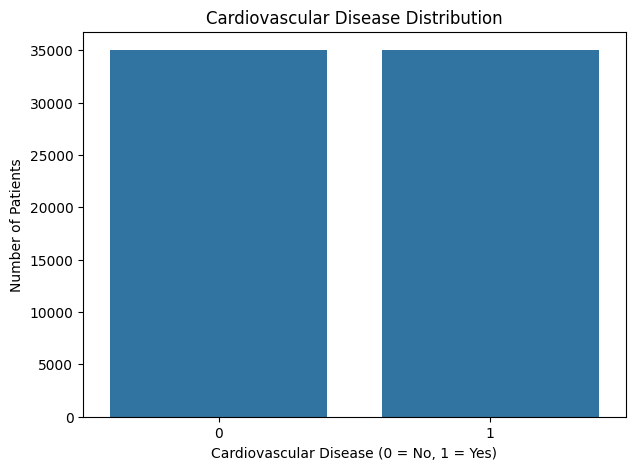

In [8]:
print("Cardiovascular Disease Distribution:")

print(df['cardio'].value_counts())

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='cardio'
)

plt.title("Cardiovascular Disease Distribution")
plt.xlabel("Cardiovascular Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")

plt.show()

In [9]:
df['age_years'] = (df['age'] / 365.25).round(1)

print("Age converted from days to years.")

display(df[['age', 'age_years']].head())

Age converted from days to years.


,age,age_years
0,18393,50.4
1,20228,55.4
2,18857,51.6
3,17623,48.2
4,17474,47.8


In [10]:
print("Shape Before Data Cleaning:", df.shape)

# Remove impossible or implausible measurements
df = df[
    (df['height'].between(120, 220)) &
    (df['weight'].between(30, 200)) &
    (df['ap_hi'].between(80, 240)) &
    (df['ap_lo'].between(40, 160)) &
    (df['ap_hi'] > df['ap_lo'])
].copy()

print("Shape After Data Cleaning:", df.shape)

print("Data cleaning completed.")

Shape Before Data Cleaning: (70000, 14)
Shape After Data Cleaning: (68608, 14)
Data cleaning completed.


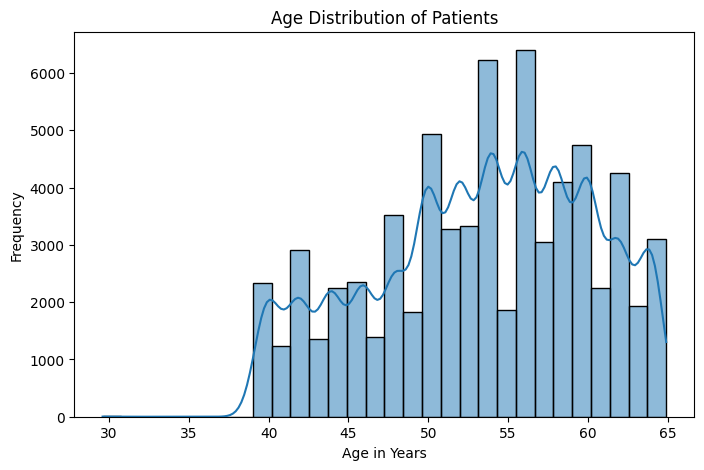

In [11]:
# Age distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='age_years',
    bins=30,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age in Years")
plt.ylabel("Frequency")

plt.show()

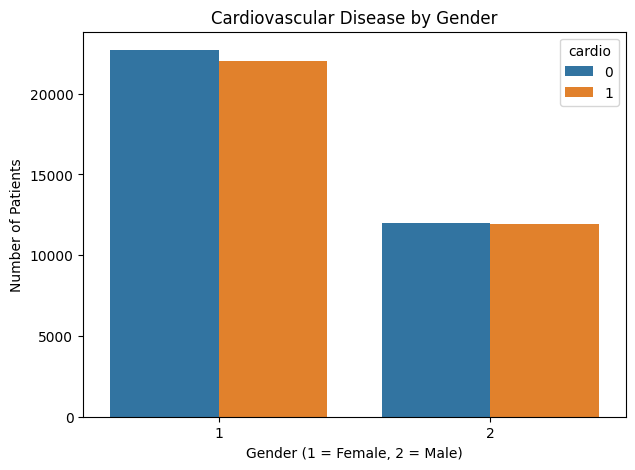

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='gender',
    hue='cardio'
)

plt.title("Cardiovascular Disease by Gender")
plt.xlabel("Gender (1 = Female, 2 = Male)")
plt.ylabel("Number of Patients")

plt.show()

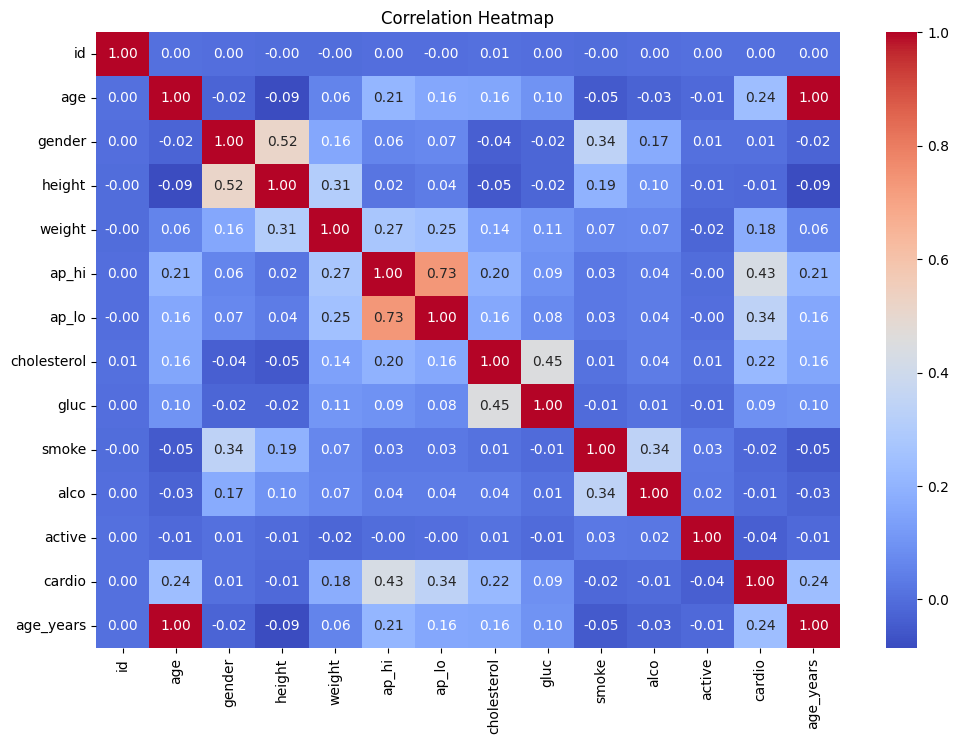

In [13]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

## 2. Feature Selection

The target variable is cardio.

The input features include:
- Age
- Gender
- Height
- Weight
- Systolic Blood Pressure
- Diastolic Blood Pressure
- Cholesterol
- Glucose
- Smoking
- Alcohol Consumption
- Physical Activity

The ID column is excluded because it is only an identifier
and does not represent a meaningful health characteristic.

In [14]:
# Selecting input features

X = df.drop(
    columns=['cardio', 'id', 'age']
)

# Selecting target variable

y = df['cardio']

print("Input Features Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

Input Features Shape: (68608, 11)
Target Shape: (68608,)

Input Features:
['gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'age_years']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (54886, 11)
Testing Data: (13722, 11)

Training Target Distribution:
cardio
0    0.505284
1    0.494716
Name: proportion, dtype: float64

Testing Target Distribution:
cardio
0    0.505247
1    0.494753
Name: proportion, dtype: float64


In [16]:
models = {

    "Decision Tree": Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', DecisionTreeClassifier(
            max_depth=10,
            random_state=42
        ))
    ]),

    "Naive Bayes": Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', GaussianNB())
    ]),

    "KNN": Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "ANN": Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation='relu',
            solver='adam',
            max_iter=300,
            early_stopping=True,
            random_state=42
        ))
    ])

}

print("All four classification models defined successfully!")

All four classification models defined successfully!


In [17]:
trained_models = {}

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "training completed.\n")

print("All models trained successfully!")

Training: Decision Tree
Decision Tree training completed.

Training: Naive Bayes
Naive Bayes training completed.

Training: KNN
KNN training completed.

Training: ANN
ANN training completed.

All models trained successfully!


In [18]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    print(name, "predictions completed.")

print("\nAll predictions generated successfully!")

Decision Tree predictions completed.
Naive Bayes predictions completed.
KNN predictions completed.
ANN predictions completed.

All predictions generated successfully!


In [19]:
results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")

display(
    results_df.sort_values(
        by='F1-Score',
        ascending=False
    )
)

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
3,ANN,0.735534,0.753368,0.692002,0.721382
0,Decision Tree,0.727809,0.758463,0.660038,0.705836
2,KNN,0.696473,0.697948,0.681396,0.689573
1,Naive Bayes,0.709882,0.762528,0.600678,0.671995


In [20]:
for name, y_pred in predictions.items():

    print("\n", "=" * 50)
    print("Classification Report:", name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                'No Cardiovascular Disease',
                'Cardiovascular Disease'
            ],
            zero_division=0
        )
    )


Classification Report: Decision Tree
                           precision    recall  f1-score   support

No Cardiovascular Disease       0.70      0.79      0.75      6933
   Cardiovascular Disease       0.76      0.66      0.71      6789

                 accuracy                           0.73     13722
                macro avg       0.73      0.73      0.73     13722
             weighted avg       0.73      0.73      0.73     13722


Classification Report: Naive Bayes
                           precision    recall  f1-score   support

No Cardiovascular Disease       0.68      0.82      0.74      6933
   Cardiovascular Disease       0.76      0.60      0.67      6789

                 accuracy                           0.71     13722
                macro avg       0.72      0.71      0.71     13722
             weighted avg       0.72      0.71      0.71     13722


Classification Report: KNN
                           precision    recall  f1-score   support

No Cardiovascular Di

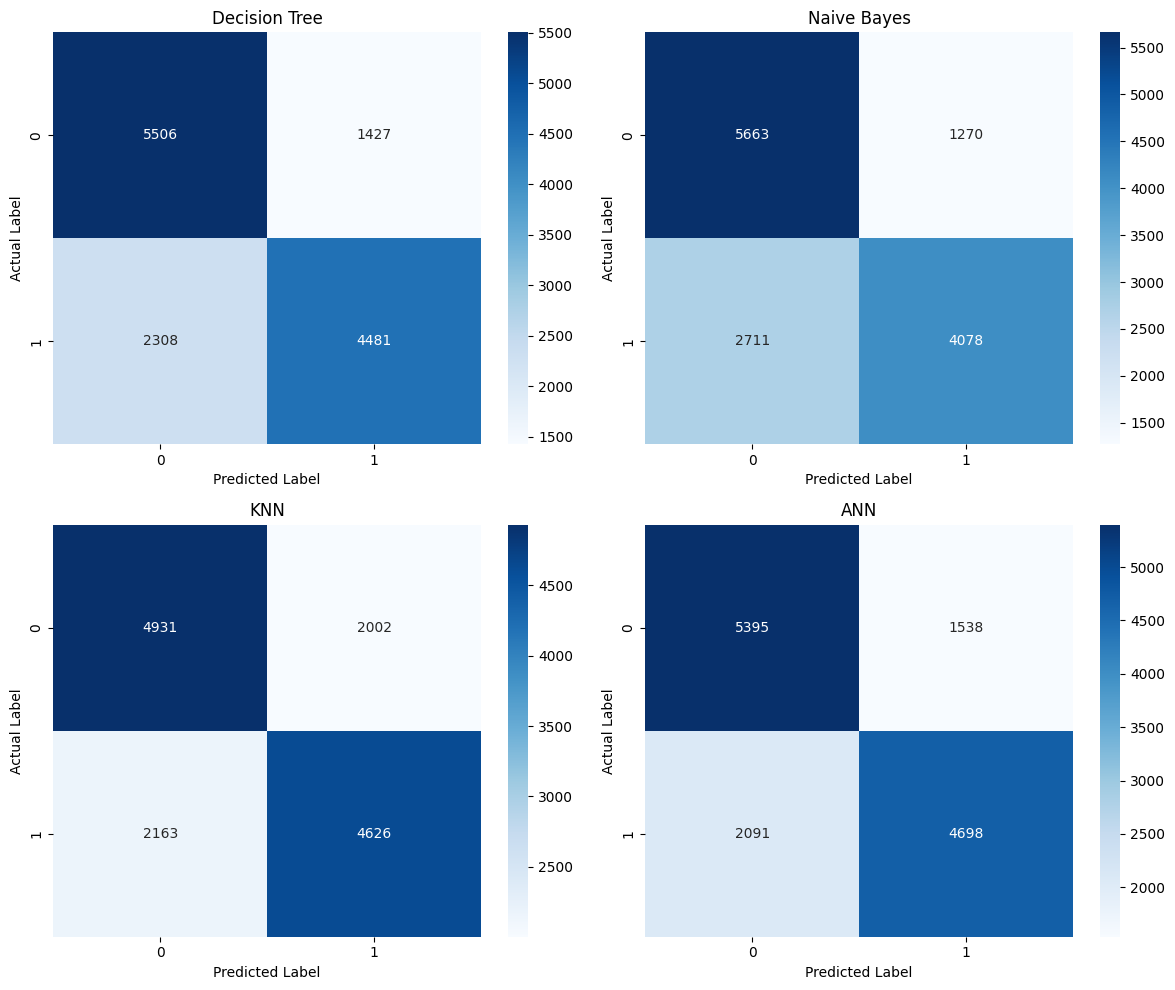

In [21]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.tight_layout()

plt.show()

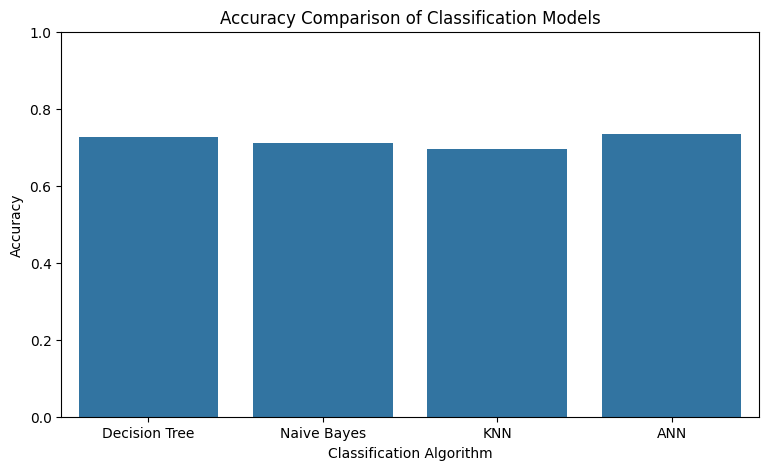

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Accuracy Comparison of Classification Models")

plt.ylabel("Accuracy")
plt.xlabel("Classification Algorithm")

plt.ylim(0, 1)

plt.show()

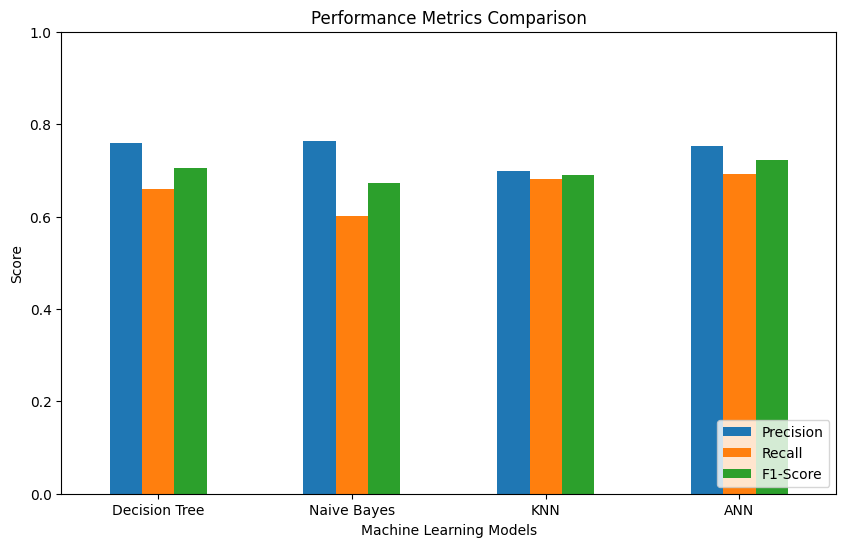

In [23]:
comparison = results_df.set_index('Model')[
    ['Precision', 'Recall', 'F1-Score']
]

comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Performance Metrics Comparison")

plt.ylabel("Score")
plt.xlabel("Machine Learning Models")

plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.legend(loc='lower right')

plt.show()

In [24]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1'
]

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'CV Accuracy': scores['test_accuracy'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV Recall': scores['test_recall'].mean(),
        'CV F1-Score': scores['test_f1'].mean()
    })

cv_df = pd.DataFrame(cv_results)

print("5-Fold Cross Validation Results:")

display(cv_df)

5-Fold Cross Validation Results:


,Model,CV Accuracy,CV Precision,CV Recall,CV F1-Score
0,Decision Tree,0.722844,0.740389,0.677384,0.707464
1,Naive Bayes,0.712039,0.763023,0.606195,0.675613
2,KNN,0.693292,0.694445,0.678636,0.686437
3,ANN,0.732810,0.746380,0.697197,0.720786


,Feature,Importance
3,ap_hi,0.675638
10,age_years,0.142442
5,cholesterol,0.069392
2,weight,0.043392
1,height,0.025164
4,ap_lo,0.016381
6,gluc,0.010829
9,active,0.008898
7,smoke,0.003238
0,gender,0.003008


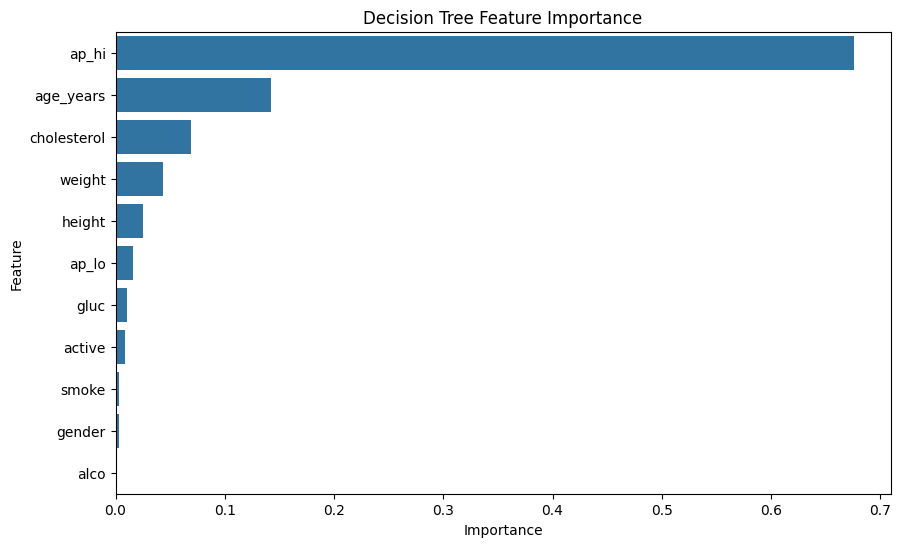

In [25]:
decision_tree = trained_models['Decision Tree']

dt_classifier = decision_tree.named_steps['classifier']

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

display(importance_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Decision Tree Feature Importance")

plt.show()

,Feature,Importance
3,ap_hi,0.143238
5,cholesterol,0.028003
10,age_years,0.025485
4,ap_lo,0.006309
9,active,0.003045
2,weight,0.001603
1,height,0.001314
7,smoke,0.000567
0,gender,0.000104
8,alco,-0.000698


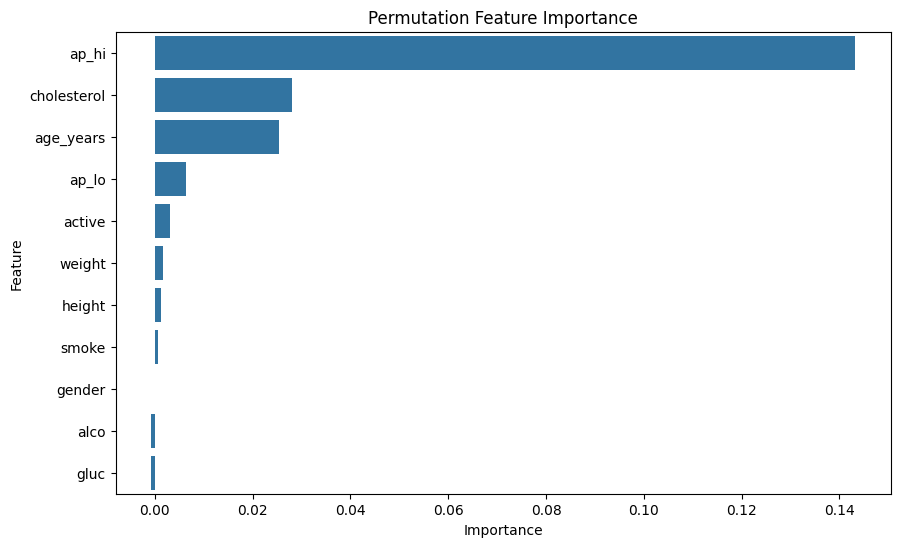

In [26]:
best_candidate_name = results_df.sort_values(
    by='F1-Score',
    ascending=False
).iloc[0]['Model']

best_candidate = trained_models[best_candidate_name]

permutation = permutation_importance(
    best_candidate,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring='f1',
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': permutation.importances_mean
}).sort_values(
    by='Importance',
    ascending=False
)

display(permutation_df)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=permutation_df,
    x='Importance',
    y='Feature'
)

plt.title("Permutation Feature Importance")

plt.show()

## 3. Feature Importance Analysis

Feature importance is used to understand which patient
characteristics contribute most to the model's predictions.

Decision Tree feature importance and permutation importance
are used for interpretation.

These importance scores describe model behaviour and do not
establish medical causation or individual clinical risk.

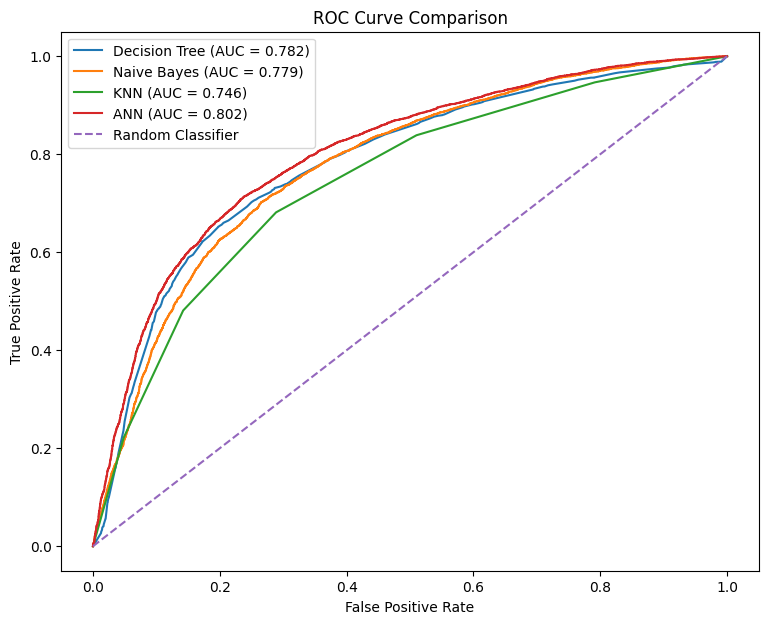

In [27]:
plt.figure(figsize=(9, 7))

for name, model in trained_models.items():

    y_probability = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_probability
    )

    auc_score = roc_auc_score(
        y_test,
        y_probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title("ROC Curve Comparison")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.show()

In [28]:
final_comparison = results_df.merge(
    cv_df,
    on='Model'
)

final_comparison = final_comparison.sort_values(
    by='F1-Score',
    ascending=False
)

print("FINAL MODEL COMPARISON")

display(final_comparison)

best_model_name = final_comparison.iloc[0]['Model']

print("\nBest Model Based on Test F1-Score:",
      best_model_name)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,CV Accuracy,CV Precision,CV Recall,CV F1-Score
3,ANN,0.735534,0.753368,0.692002,0.721382,0.732810,0.746380,0.697197,0.720786
0,Decision Tree,0.727809,0.758463,0.660038,0.705836,0.722844,0.740389,0.677384,0.707464
2,KNN,0.696473,0.697948,0.681396,0.689573,0.693292,0.694445,0.678636,0.686437
1,Naive Bayes,0.709882,0.762528,0.600678,0.671995,0.712039,0.763023,0.606195,0.675613



Best Model Based on Test F1-Score: ANN


In [29]:
model_description = {
    'Decision Tree':
        'Easy to interpret but may overfit the training data.',

    'Naive Bayes':
        'Fast and simple but assumes conditional independence.',

    'KNN':
        'Simple and effective but can be computationally expensive.',

    'ANN':
        'Can learn complex patterns but requires tuning and more computation.'
}

for name, description in model_description.items():

    print("\n", name)
    print(description)


 Decision Tree
Easy to interpret but may overfit the training data.

 Naive Bayes
Fast and simple but assumes conditional independence.

 KNN
Simple and effective but can be computationally expensive.

 ANN
Can learn complex patterns but requires tuning and more computation.


In [30]:
print("=" * 55)
print("CARDIOVASCULAR DISEASE PREDICTION")
print("FINAL PROJECT SUMMARY")
print("=" * 55)

print("\nDataset Records Used:", len(df))

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("\nAlgorithms Implemented:")

for name in models.keys():
    print("-", name)

print("\nModel Performance:")

display(
    results_df.sort_values(
        by='F1-Score',
        ascending=False
    )
)

print("\nBest Model Based on Test F1-Score:",
      best_model_name)

print("\nProject execution completed successfully!")

CARDIOVASCULAR DISEASE PREDICTION
FINAL PROJECT SUMMARY

Dataset Records Used: 68608
Training Records: 54886
Testing Records: 13722

Algorithms Implemented:
- Decision Tree
- Naive Bayes
- KNN
- ANN

Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score
3,ANN,0.735534,0.753368,0.692002,0.721382
0,Decision Tree,0.727809,0.758463,0.660038,0.705836
2,KNN,0.696473,0.697948,0.681396,0.689573
1,Naive Bayes,0.709882,0.762528,0.600678,0.671995



Best Model Based on Test F1-Score: ANN

Project execution completed successfully!


In [31]:
df.to_csv(
    'cleaned_cardio_data.csv',
    index=False
)

results_df.to_csv(
    'cardiovascular_model_comparison.csv',
    index=False
)

cv_df.to_csv(
    'cardiovascular_cross_validation.csv',
    index=False
)

print("All output files exported successfully!")

All output files exported successfully!


In [32]:
from google.colab import files

files.download('cleaned_cardio_data.csv')

files.download('cardiovascular_model_comparison.csv')

files.download('cardiovascular_cross_validation.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>